# A fair mid for related prediction markets: blockade, ceasefire and Hormuz

Three related ladders on Polymarket, priced every hour since 20 October 2026:

| ladder | contract | type |
|---|---|---|
| **blockade** | *US announces end of Iranian blockade by …?* | event by date |
| **ceasefire** | *Israel x Iran ceasefire continues through …?* | holds through date |
| **Hormuz** | *Strait of Hormuz traffic returns to normal by …?* (since 14 November) | event by date |

This notebook applies a **generic model for $K$ related ladders**
([`market_factor.py`](market_factor.py)) and asks:

1. how do the hazard curves of the three events move together, within each
   curve and across curves;
2. what is the **fair mid** of each contract, from its own ladder and the
   related ones;
3. does a gap between a price and its fair mid **predict the next 1 or 3
   hours**, and does the information from the other events add to it?

The hourly prices come from Polymarket's public API (`prices-history`,
one point per hour) and are saved in `data/`; the notebook runs offline.

## 1. Theory

### Observation

A contract of ladder $k$ observed at hour $t$ with deadline $T$ has, on the
complementary log-log scale ($H = -\log(1-p)$ for "by" contracts,
$H = -\log p$ for "holds through" ones),

$$
y = \log H = \log \sum_j L_j\, e^{a_{k,j} + n_k(t)\,\phi_j} + m_k(t) + \varepsilon,
\qquad \mathrm{sd}(\varepsilon) = \frac{\tau_k}{H e^{-H}},
$$

- $L_j$: days of calendar bin $j$ (between the deadlines of the ladder)
  between $t$ and $T$;
- $a_k$: baseline log-hazards of the ladder;
- $m_k(t)$: **level** factor, which shifts the whole hazard curve;
- $n_k(t)$: **front** factor, with weight $\phi_j = e^{-d_j/\ell}$ for a bin
  $d_j$ days ahead ($\ell = 14$ days): it moves the near end of the curve more
  than the far end;
- $\varepsilon$: price noise of $\tau_k$ probability points, carried to this
  scale by the delta method.

The level and front factors are the shape factors of the curve, as level
and slope are for a yield curve. Hormuz has no front factor: all its contracts
are months away.

**Monotone by construction.** The cumulative hazard is a sum of positive
terms, so for any value of the factors the fair probability of "by $T$"
increases with $T$ and that of "holds through $T$" decreases. A far contract
can never be fair above a nearer one.

### State and correlations

The factors $x = (m_1, \dots, m_K, n_{k_1}, \dots)$ follow a random walk,

$$
x(t) = x(t-1) + \eta_t, \qquad \eta_t \sim \mathcal N(0, \Sigma),
$$

with $\Sigma$ the full covariance of the hourly moves: **within** each curve
(level against front) and **across** curves. The best estimate of the move of
one factor given the others is the regression

$$
\mathbb E[\eta_i \mid \eta_{-i}] = \Sigma_{i,-i}\,\Sigma_{-i,-i}^{-1}\,\eta_{-i} .
$$

### Fair mid

The (extended) Kalman filter gives the real-time state
$\hat x(t) = \mathbb E[x(t) \mid \text{all prices up to } t]$; the fair mid of
a contract is its price on that curve,

$$
\hat p = F\Big(\sum_j L_j\, e^{\hat a_{k,j} + \hat n_k \phi_j + \hat m_k}\Big),
\qquad F(H) = 1 - e^{-H} \text{ (by)},\ e^{-H} \text{ (holds)} .
$$

It pools the contract's own price, the other contracts of its ladder and, through
$\Sigma$, the other ladders, each weighted by its precision. The fair mid
**from its own ladder only** is the same filter with $\Sigma$ restricted to
blocks within each ladder; the difference between the two is what the other
events add.

### Contracts that open and close

The factors describe the **hazard curve**, not individual contracts.
- **A contract is an observation of the curve.** As contracts expire and new
  ones are listed, only the set of observations changes from one hour to the
  next: the rows of the observation matrix. The state, $\Sigma$ and $\tau$
  keep their meaning.
- **The front factor is defined by horizon** ($e^{-d/\ell}$ for $d$ days
  ahead), so it rolls with time: "the next two weeks" always means the same
  thing.
- **A ladder that starts late** (Hormuz, on 14 November) simply has its
  factors unobserved before: the filter carries them with growing variance
  until the first prices arrive.

What does need care:
- **The calendar baselines.** A new deadline splits a bin, and the new pieces
  start from the baseline of the bin they split. In the strict test below the
  baselines estimated on the training period are mapped onto the bins of the
  later contracts this way.
- **A constant $\Sigma$.** It assumes the co-movement does not change as
  deadlines approach or as the news regime changes. Weighting the EM moments
  with exponential forgetting would let it drift over time.

### Estimation, with exact derivatives

- **$\Sigma$ and $\tau$**: EM, with closed-form updates from the smoothed
  moments: $\hat\Sigma$ is the average of $\mathbb E[\Delta x\,\Delta x^\top]$,
  using the lag-one covariances of the smoother, and $\hat\tau_k^2$ the average
  of $g^2\,\mathbb E[(y - h(x))^2]$. Each step is one pass of the smoother.
- **Refinement and standard errors**: the exact score of every hour, from a
  *tangent filter* that carries $\partial x$ and $\partial P$ through the
  recursions, gives scoring steps $\theta \leftarrow \theta + I^{-1} g$ and the
  covariance $I^{-1}$, with $I = \sum_t s_t s_t^\top$ (BHHH). No finite
  differences: they appear only once, below, to check the exact gradient.
- **Baselines** $a_k$: weighted least squares given the smoothed factors,
  fitted by `maxlike` with its exact Hessian.

### The predictive test

With $q_t$ the market price, the target is the change $q_{t+h} - q_t$
($h = 1, 3$ hours), regressed on

$$
\underbrace{\hat p^{\text{own}}_t - q_t}_{\text{gap to the own-ladder fair mid}}
\quad\text{and}\quad
\underbrace{\hat p_t - \hat p^{\text{own}}_t}_{\text{what the other events add}},
$$

with standard errors clustered by hour (all contracts of an hour share
news). A slope of 1 would mean the whole gap closes within $h$ hours. The fair
mid at $t$ uses only prices up to $t$. For a strict test, the parameters are
estimated on the first 60% of the hours and the test is run on the remaining
40%.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2, SEQUENTIAL
import market_factor as mf

ps.apply()
hourly = pd.read_csv("data/polymarket_iran_hourly.csv", parse_dates=["deadline", "hour", "time"])
hourly = hourly.drop(columns="time").rename(columns={"hour": "time"})
snap = pd.read_csv("data/polymarket_iran_snapshot3.csv", parse_dates=["deadline"])
KINDS = {"blockade": "by", "ceasefire": "through", "hormuz": "by"}
COLORS = {"blockade": BLUE, "ceasefire": ORANGE, "hormuz": AQUA}
FRONT = ["blockade", "ceasefire"]

def date_label(d, fmt="%d %b"):
    return (pd.Timestamp(d) - pd.Timedelta(hours=28)).strftime(fmt)

print(hourly.groupby("ladder").agg(contracts=("deadline", "nunique"), prices=("price", "size"),
                                   first=("time", "min"), last=("time", "max")))

           contracts  prices               first                last
ladder                                                              
blockade           9    3189 2026-10-20 06:00:00 2026-11-20 05:00:00
ceasefire         22    6087 2026-10-20 06:00:00 2026-11-20 05:00:00
hormuz             4     560 2026-11-14 03:00:00 2026-11-20 05:00:00


## 2. Data

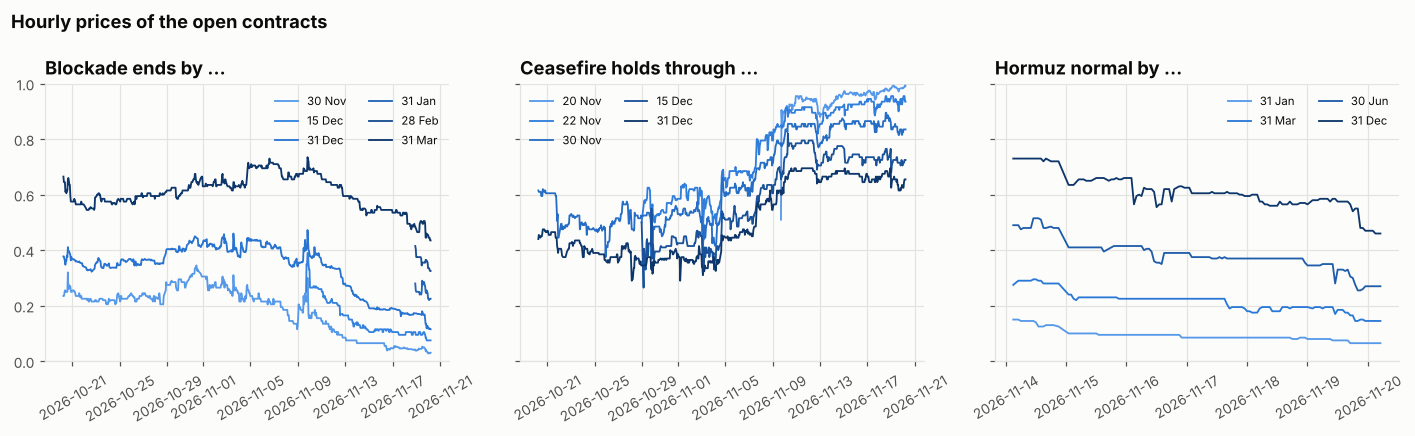

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, lad in zip(axes, KINDS):
    open_dl = snap.loc[snap.ladder == lad, "deadline"].sort_values().values
    shades = SEQUENTIAL(np.linspace(0.35, 1, len(open_dl)))
    for dl, c in zip(open_dl, shades):
        s = hourly[(hourly.ladder == lad) & (hourly.deadline == dl)]
        ax.plot(s["time"], s["price"], color=c, lw=1.2, label=date_label(dl))
    ax.set_title({"blockade": "Blockade ends by …", "ceasefire": "Ceasefire holds through …",
                  "hormuz": "Hormuz normal by …"}[lad])
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=7.5, ncol=2, loc="best")
ax.set_ylim(0, 1)
fig.suptitle("Hourly prices of the open contracts", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

The Hormuz market is young and thin (a few thousand dollars traded per
contract); its prices move in steps. Its correlations will be the least
precise.

## 3. Fits: level only, and level + front

In [3]:
level = mf.Ladders(hourly, KINDS).fit_em(n_iter=300).refine(n_steps=30)
shape = mf.Ladders(hourly, KINDS, front=14., front_ladders=FRONT).fit_em(n_iter=300).refine(n_steps=60)

def check_gradient(model, n_check=6, h=1e-5):
    """verification only: the exact gradient against central differences"""
    ll, s = model.scores()
    g = s.sum(0)
    f = lambda x: model.kalman(model.a, *model.unpack(x))["loglik"]
    err = 0.
    for i in np.linspace(0, model.x.size - 1, n_check).astype(int):
        e = np.zeros_like(model.x); e[i] = h
        err = max(err, abs((f(model.x + e) - f(model.x - e)) / (2 * h) - g[i]) / (1 + abs(g[i])))
    return err, np.abs(g).max()

rows = []
for name, m in (("level only", level), ("level + front", shape)):
    err, gmax = check_gradient(m)
    rows.append({"model": name, "factors": m.D, "parameters": m.x.size,
                 "log-likelihood": m.loglik, "largest |gradient|": gmax,
                 "exact vs numerical gradient (rel. error)": err})
pd.DataFrame(rows).set_index("model").round({"log-likelihood": 1, "largest |gradient|": 2})

,factors,parameters,log-likelihood,largest |gradient|,exact vs numerical gradient (rel. error)
model,,,,,
level only,3,9,1699.8,0.63,1.073160e-05
level + front,5,18,4859.8,637.80,1.526446e-07


The front factor raises the log-likelihood by about 3,000 for 9 more
parameters: the hazard curves do not move in parallel, their near ends move
much more than their far ends.

The exact gradients match central differences to about $10^{-6}$. The
level-only model is converged. The level + front model still has a sizeable
gradient after the scoring steps, along the direction where the ceasefire's level
and front move against each other (correlation close to $-1$). Its likelihood
surface is flat there, and the estimates below are close to, not at, the
maximum.

**Price noise** ($\tau$, probability points) and **hourly volatility of the
factors**:

In [4]:
names = list(KINDS)
state_names = names + ["%s front" % n for n in FRONT]
pd.DataFrame({"noise tau (points)": 100 * shape.tau}, index=names).round(2).join(
    pd.DataFrame({"hourly sd of factor": np.sqrt(np.diag(shape.Sigma))}, index=state_names), how="outer").round(4)

,noise tau (points),hourly sd of factor
blockade,1.11,0.0149
blockade front,NaN,0.0904
ceasefire,2.32,0.1324
ceasefire front,NaN,0.3696
hormuz,1.10,0.0256


## 4. How the curves move together

The factors are hard to read on their own; what matters is how the hazard
**at a given horizon** moves: for ladder $k$ at $d$ days ahead,
$\Delta \log h_k(d) = \Delta m_k + e^{-d/\ell}\,\Delta n_k$. Correlations of
the hourly moves at 1 week and at 3 months (the ceasefire ladder ends on 31
December, so 1 month there), with 95% intervals from the BHHH covariance of the
parameters:

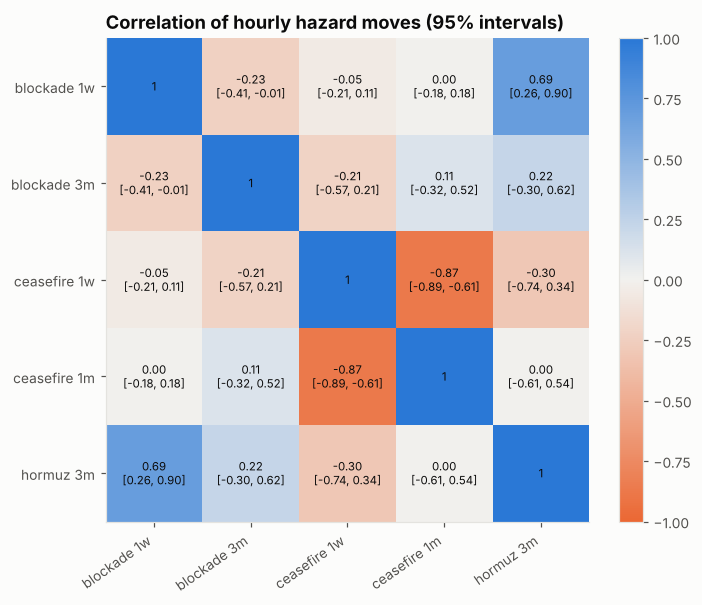

In [5]:
ell = 14.
horizons = [("blockade", 7), ("blockade", 90), ("ceasefire", 7), ("ceasefire", 30), ("hormuz", 90)]
labels = ["%s %s" % (n, "1w" if d == 7 else ("1m" if d == 30 else "3m")) for n, d in horizons]
A = np.zeros((len(horizons), shape.D))
for r, (n, d) in enumerate(horizons):
    k = names.index(n)
    A[r, k] = 1
    if shape.fidx[k] >= 0:
        A[r, shape.fidx[k]] = np.exp(-d / ell)

def horizon_corr(Sigma):
    C = A @ Sigma @ A.T
    s = np.sqrt(np.diag(C))
    return C / np.outer(s, s)

cov = shape.hyper_cov()
draws = np.random.default_rng(0).multivariate_normal(shape.x, cov, 3000)
cs = np.array([horizon_corr(shape.unpack(d)[0]) for d in draws])
corr = horizon_corr(shape.Sigma)
lo, hi = np.quantile(cs, .025, 0), np.quantile(cs, .975, 0)

fig, ax = plt.subplots(figsize=(6.6, 5.6))
diverging = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "div", ["#eb6834", "#f2f1ee", "#2a78d6"])
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, "%.2f\n[%.2f, %.2f]" % (corr[i, j], lo[i, j], hi[i, j]) if i != j else "1",
                ha="center", va="center", fontsize=7.5)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.grid(False)
ax.set_title("Correlation of hourly hazard moves (95% intervals)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

Reading the matrix:

- **Within a curve**:
  - the near and far ends of the blockade curve barely move together
    (−0.23);
  - for the ceasefire they move in **opposite** directions (−0.87). News
    shifts the risk between the next days and the following weeks (a
    breakdown expected sooner or later) more than it changes the total risk.
  - A single level factor cannot represent either.
  - This is also the direction in which the fit is least converged, so the
    exact value is uncertain.
- **Across curves** the clearest link is between the near blockade hazard and
  the Hormuz hazard: +0.69, with a 95% interval of [0.26, 0.90]. News of an end
  of the blockade moves the expected reopening of the strait with it. The
  other cross-event intervals include zero after one month of hourly data, and
  only six days for Hormuz.

The regressions implied by $\Sigma$, for the level factors: the expected
hourly move of each curve given the moves of the other two.

In [6]:
pd.DataFrame(corr, index=labels, columns=labels).round(2)

,blockade 1w,blockade 3m,ceasefire 1w,ceasefire 1m,hormuz 3m
blockade 1w,1.00,-0.23,-0.05,0.00,0.69
blockade 3m,-0.23,1.00,-0.21,0.11,0.22
ceasefire 1w,-0.05,-0.21,1.00,-0.87,-0.30
ceasefire 1m,0.00,0.11,-0.87,1.00,0.00
hormuz 3m,0.69,0.22,-0.30,0.00,1.00


In [7]:
B = level.regressions()
pd.DataFrame(B, index=["E[%s | others]" % n for n in names], columns=names).round(3)

,blockade,ceasefire,hormuz
E[blockade | others],NaN,0.042,0.461
E[ceasefire | others],0.681,NaN,-1.064
E[hormuz | others],0.947,-0.133,NaN


## 5. Fair mid today

In [8]:
xf = shape.kalman(shape.a, shape.Sigma, shape.tau)["filtered"]
last = xf[:, -1]
rows = []
for _, c in snap.sort_values(["ladder", "deadline"]).iterrows():
    k = names.index(c["ladder"])
    tt = np.array([np.datetime64(shape.grid[-1])])
    L = shape._exposure(tt, np.array([c["deadline"].to_datetime64()]), k)[0]
    e = shape.edges[k]
    lo_ = np.maximum(tt[0], e[:-1]); hi_ = np.minimum(c["deadline"].to_datetime64(), e[1:])
    d_mid = np.maximum(((lo_ + (hi_ - lo_) / 2) - tt[0]) / np.timedelta64(1, "D"), 0)
    n = last[shape.fidx[k]] if shape.fidx[k] >= 0 else 0.
    H = np.sum(L * np.exp(shape.a[k] + n * np.exp(-d_mid / 14.))) * np.exp(last[k])
    fair = -np.expm1(-H) if KINDS[c["ladder"]] == "by" else np.exp(-H)
    rows.append({"ladder": c["ladder"], "date": date_label(c["deadline"], "%d %b %Y"),
                 "bid": c["bid"], "ask": c["ask"], "fair mid": fair,
                 "fair - mid (points)": 100 * (fair - (c["bid"] + c["ask"]) / 2)})
fair_now = pd.DataFrame(rows)
fair_now.round(3)

,ladder,date,bid,ask,fair mid,fair - mid (points)
0,blockade,30 Nov 2026,0.030,0.031,0.021,-0.953
1,blockade,15 Dec 2026,0.070,0.080,0.066,-0.863
2,blockade,31 Dec 2026,0.112,0.119,0.140,2.494
3,blockade,31 Jan 2027,0.220,0.230,0.222,-0.306
4,blockade,28 Feb 2027,0.320,0.330,0.328,0.349
5,blockade,31 Mar 2027,0.430,0.440,0.437,0.156
6,ceasefire,20 Nov 2026,0.985,0.987,0.985,-0.087
7,ceasefire,22 Nov 2026,0.930,0.940,0.934,-0.106
8,ceasefire,30 Nov 2026,0.830,0.840,0.843,0.797
9,ceasefire,15 Dec 2026,0.720,0.730,0.718,-0.745


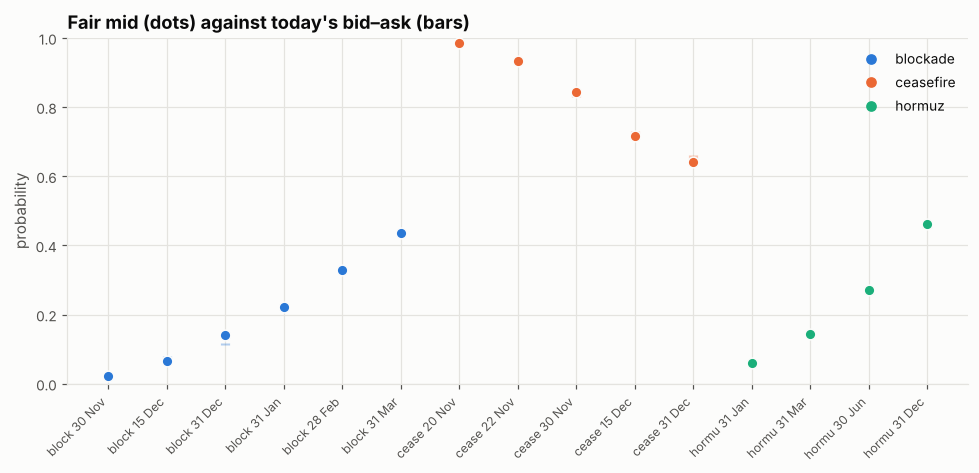

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.4))
xx = np.arange(len(fair_now))
for i, r in fair_now.iterrows():
    color = COLORS[r["ladder"]]
    ax.vlines(i, r["bid"], r["ask"], color=color, lw=6, alpha=.35)
    ax.plot(i, r["fair mid"], "o", color=color, markersize=7, markeredgecolor="#fcfcfb")
ax.set_xticks(xx)
ax.set_xticklabels([r["ladder"][:5] + " " + r["date"][:6] for _, r in fair_now.iterrows()],
                   rotation=45, ha="right", fontsize=8)
ax.set_ylim(0, 1)
for lad, color in COLORS.items():
    ax.plot([], [], "o", color=color, label=lad)
ps.finish(ax, "Fair mid (dots) against today's bid–ask (bars)", None, "probability", legend=True)

## 6. Does the fair mid predict the next hours?

In [10]:
def panel(model):
    fm, own = model.fair_mid(), model.fair_mid(own_only=True)
    x = model.data.assign(q=model.q, own_gap=own - model.q, cross_gap=fm - own)
    return x.sort_values(["ladder", "deadline", "t"])

def regress(x, h, mask=None):
    g = x.groupby(["ladder", "deadline"])
    fut, dt = g["q"].shift(-h), g["t"].shift(-h) - x["t"]
    ok = (dt == h) & fut.notna()
    if mask is not None:
        ok &= mask
    y = (fut - x["q"])[ok].values
    X = np.column_stack([np.ones(ok.sum()), x.loc[ok, "own_gap"], x.loc[ok, "cross_gap"]])
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    cl = x.loc[ok, "t"].values
    XtXi = np.linalg.inv(X.T @ X)
    meat = np.zeros((3, 3))
    for c in np.unique(cl):
        sc = X[cl == c].T @ e[cl == c]
        meat += np.outer(sc, sc)
    se = np.sqrt(np.diag(XtXi @ meat @ XtXi))
    return {"n": int(ok.sum()), "own gap": b[1], "se own": se[1],
            "other events": b[2], "se other": se[2]}

rows = []
for mname, m in (("level only", level), ("level + front", shape)):
    x = panel(m)
    for h in (1, 3):
        rows.append({"model": mname, "hours ahead": h, "contracts": "all", **regress(x, h)})
        for lad in names:
            rows.append({"model": mname, "hours ahead": h, "contracts": lad,
                         **regress(x, h, x["ladder"] == lad)})
in_sample = pd.DataFrame(rows).set_index(["model", "hours ahead", "contracts"])
in_sample.round(3)

n  own gap  se own  other events  \
model         hours ahead contracts                                        
level only    1           all        8347    0.185   0.047         0.609   
                          blockade   2966    0.051   0.011         0.199   
                          ceasefire  4845    0.274   0.066         1.162   
                          hormuz      536    0.236   0.067         0.950   
              3           all        7670    0.254   0.046         0.919   
                          blockade   2709    0.115   0.020         0.310   
                          ceasefire  4453    0.367   0.063         1.572   
                          hormuz      508    0.473   0.070         2.659   
level + front 1           all        8347    0.217   0.028         0.530   
                          blockade   2966    0.147   0.023         0.403   
                          ceasefire  4845    0.233   0.035         0.575   
                          hormuz      536    0.237   0.068         1.126   
              3           all        7670    0.291   0.031         0.667   
                          blockade   2709    0.289   0.032         0.665   
                          ceasefire  4453    0.305   0.037         0.692   
                          hormuz      508    0.476   0.073         1.883   

                                     se other  
model         hours ahead contracts            
level only    1           all           0.139  
                          blockade      0.156  
                          ceasefire     0.330  
                          hormuz        1.398  
              3           all           0.191  
                          blockade      0.303  
                          ceasefire     0.539  
                          hormuz        3.158  
level + front 1           all           0.133  
                          blockade      0.199  
                          ceasefire     0.189  
                          hormuz        0.773  
              3           all           0.205  
                          blockade      0.394  
                          ceasefire     0.314  
                          hormuz        1.337

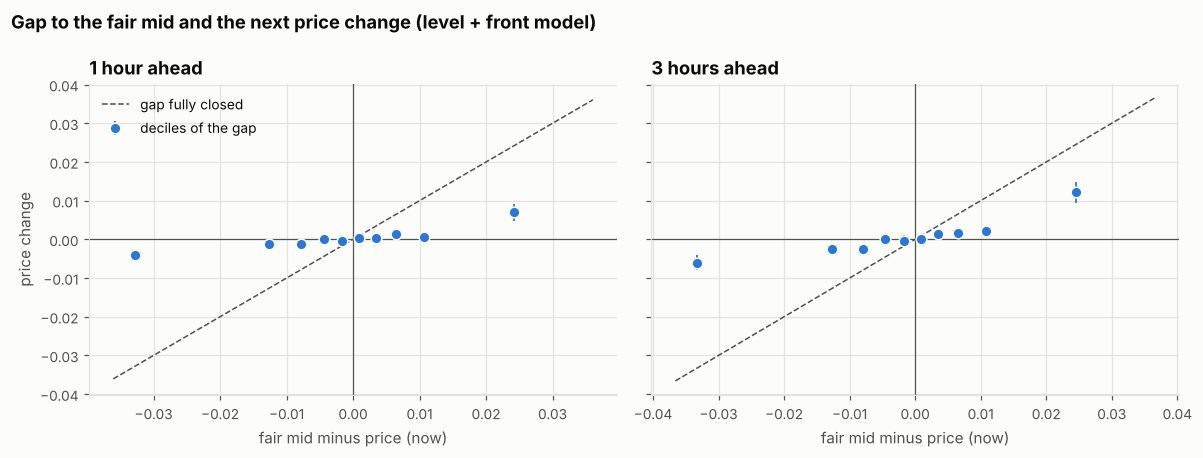

In [11]:
x = panel(shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, h in zip(axes, (1, 3)):
    g = x.groupby(["ladder", "deadline"])
    fut, dt = g["q"].shift(-h), g["t"].shift(-h) - x["t"]
    ok = (dt == h) & fut.notna()
    gap = (x["own_gap"] + x["cross_gap"])[ok]
    dq = (fut - x["q"])[ok]
    bins = pd.qcut(gap, 10, duplicates="drop")
    gr = pd.DataFrame({"gap": gap, "dq": dq}).groupby(bins, observed=True)
    lim = np.abs(gr["gap"].mean()).max() * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=TEXT_2, lw=1, ls="--", label="gap fully closed")
    ax.axhline(0, color=TEXT_2, lw=.8); ax.axvline(0, color=TEXT_2, lw=.8)
    ax.errorbar(gr["gap"].mean(), gr["dq"].mean(), yerr=1.96 * gr["dq"].std() / np.sqrt(gr["dq"].count()),
                fmt="o", color=BLUE, markersize=7, elinewidth=1.2, markeredgecolor="#fcfcfb",
                label="deciles of the gap")
    ax.set_title("%d hour%s ahead" % (h, "s" if h > 1 else ""))
    ax.set_xlabel("fair mid minus price (now)")
axes[0].set_ylabel("price change")
axes[0].legend()
fig.suptitle("Gap to the fair mid and the next price change (level + front model)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

**Strict out-of-sample test.** Hormuz has no prices in the first 60% of the
hours, so the strict test uses the blockade and ceasefire ladders: parameters
estimated on the first 60% of the hours, fair mids computed in real time over
the whole period with those parameters, and the regressions run on the
remaining 40%.

In [12]:
K2 = {"blockade": "by", "ceasefire": "through"}
h2 = hourly[hourly.ladder.isin(K2)]
full = mf.Ladders(h2, K2, front=14.)
cut = full.grid[int(.6 * len(full.grid))]
train = mf.Ladders(h2[h2.time < cut], K2, front=14.).fit_em(n_iter=300).refine(n_steps=30)
full.Sigma, full.tau = train.Sigma, train.tau
full.a = [train.a[k][np.minimum(np.searchsorted(train.edges[k][1:], full.edges[k][1:]),
                                len(train.edges[k]) - 2)] for k in range(full.K)]
x2 = panel(full)
test = x2["time"] >= cut
strict = pd.DataFrame([{"hours ahead": h, **regress(x2, h, test)} for h in (1, 3)]).set_index("hours ahead")
print("training up to", cut)
strict.round(3)

training up to 2026-11-07 20:00:00


,n,own gap,se own,other events,se other
hours ahead,,,,,
1,3214,0.172,0.035,-0.149,0.345
3,3070,0.201,0.035,-0.486,0.522


**Is it more than the bid–ask spread?** The history has no quotes, so
today's half-spread of each open contract stands in for it. For those
contracts in the test period: how often the gap exceeds the half-spread, and
the average move in the direction of the gap when it does, against the full
spread that a round trip would cost.

In [13]:
spread = snap.assign(half=(snap.ask - snap.bid) / 2).set_index(["ladder", "deadline"])["half"]
x2 = x2.join(spread, on=["ladder", "deadline"])
rows = []
for h in (1, 3):
    g = x2.groupby(["ladder", "deadline"])
    fut, dt = g["q"].shift(-h), g["t"].shift(-h) - x2["t"]
    ok = (dt == h) & fut.notna() & test & x2["half"].notna()
    gap = (x2["own_gap"] + x2["cross_gap"])[ok]
    signal = gap.abs() > x2.loc[ok, "half"]
    move = (np.sign(gap) * (fut - x2["q"])[ok])[signal]
    rows.append({"hours ahead": h, "hours x contracts": int(ok.sum()),
                 "gap beyond half-spread": signal.mean(),
                 "mean move towards fair mid (points)": 100 * move.mean(),
                 "se (points)": 100 * move.std() / np.sqrt(signal.sum()),
                 "mean full spread (points)": 100 * 2 * x2.loc[ok, "half"][signal].mean()})
pd.DataFrame(rows).set_index("hours ahead").round(3)

,hours x contracts,gap beyond half-spread,mean move towards fair mid (points),se (points),mean full spread (points)
hours ahead,,,,,
1,2502,0.709,0.131,0.032,0.713
3,2394,0.704,0.172,0.042,0.711


## 7. Conclusions

- **One framework for $K$ ladders.** Each ladder is a hazard curve with
  shape factors (level, and front where it has near contracts). The joint
  random walk of the factors carries the correlations within and across curves.
  The fair mid is the real-time filtered curve: monotone in the deadline by
  construction, and it pools each contract with its ladder and the related ones.
- **Fast, with exact derivatives.** EM steps are one smoother pass each, and
  the exact scores of the tangent filter refine the estimates and give their
  standard errors.
- **The shape matters.** Curves do not move in parallel: the front factor
  improves the fit by thousands of log-likelihood points.
- **Prediction.**
  - Prices move back towards the fair mid of their own ladder within hours:
    about 20% of the gap closes in 1 hour and 30% in 3 hours. Out of sample
    it is 17% and 20%, clearly different from zero.
  - The information from the other events looks significant within the sample
    (coefficient about 0.5–0.7), but **out of sample it vanishes** (−0.15 ± 0.35
    and −0.49 ± 0.52). With one month of hourly data the cross-event part of
    the fair mid does not yet earn its place in prediction.
  - **The moves are small against the spread**: about 0.13–0.17 points in the
    direction of the fair mid, against a full spread of about 0.7 points.
    Crossing the spread to trade on the gap would not pay. Quoting around the
    fair mid (as a market maker) is where the signal could help, but the
    history has no quotes to test that.
- **Next steps:**
  - quotes (bid and ask) instead of the price series, to measure the edge net
    of the spread;
  - more history, especially for Hormuz;
  - a curvature factor if the residuals of long ladders call for one.

*An illustration of the models, not trading advice.*